# Diabetes Health Indicators - ML Zoomcamp Midterm

**Problem.** Predict whether a person has diabetes or pre-diabetes from lifestyle and health indicators in the CDC
BRFSS 2015 survey, as a **first-stage screening tool**: the model returns a calibrated probability, and a threshold
decides who should be referred for a confirmatory blood test (HbA1c).

**Dataset.** [CDC Diabetes Health Indicators](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset)
(`diabetes_binary_health_indicators_BRFSS2015.csv`, 253,680 rows, 21 features, binary target).

**Plan of this notebook**
1. Data checks (missing values, ranges, **duplicates**) and EDA
2. Split 60/20/20 (stratified) - the test set is touched once, at the end
3. Compare 6 models, tuning two of them with 5-fold CV on the full training split
4. Select a model on the validation set, then **calibrate** probabilities and **choose the decision threshold** using
   out-of-fold predictions (never the test set)
5. Final evaluation on the test set

The modelling code lives in `train.py` (imported below), so the notebook and `python train.py` run exactly the same logic.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display
from sklearn.base import clone
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import roc_auc_score
import xgboost as xgb

import train                      # shared training code (same logic as `python train.py`)
from scoring import FEATURES

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
FIG_DIR = Path("artifacts/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
TARGET = train.TARGET

## 1. Data checks

In [2]:
raw = pd.read_csv(train.DATA_PATH)
raw.columns = [c.lower() for c in raw.columns]
print("shape:", raw.shape)
print("missing values:", int(raw.isnull().sum().sum()))
display(raw.head())
display(raw.describe().T[["min", "mean", "max"]].round(2))

shape: (253680, 22)
missing values: 0


,diabetes_binary,highbp,highchol,cholcheck,bmi,smoker,stroke,heartdiseaseorattack,physactivity,fruits,...,anyhealthcare,nodocbccost,genhlth,menthlth,physhlth,diffwalk,sex,age,education,income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


,min,mean,max
diabetes_binary,0.0,0.14,1.0
highbp,0.0,0.43,1.0
highchol,0.0,0.42,1.0
cholcheck,0.0,0.96,1.0
bmi,12.0,28.38,98.0
smoker,0.0,0.44,1.0
stroke,0.0,0.04,1.0
heartdiseaseorattack,0.0,0.09,1.0
physactivity,0.0,0.76,1.0
fruits,0.0,0.63,1.0


No missing values and every column is numeric, but the value ranges matter: they become the validation rules of the API
(`scoring.FEATURE_SPECS`). BMI ranges from 12 to 98 - extreme but plausible survey answers, so we keep them (tree models
are insensitive to them; logistic regression gets a `StandardScaler`).

### 1.1 Duplicate rows

In [3]:
n_dup = int(raw.duplicated().sum())
print(f"Exact duplicate rows: {n_dup:,} ({n_dup / len(raw):.1%})")
print(f"Positive rate - all rows: {raw[TARGET].mean():.3f} | duplicate rows only: {raw[raw.duplicated()][TARGET].mean():.3f}")

feat_cols = [c for c in raw.columns if c != TARGET]
profiles = raw.groupby(feat_cols)[TARGET].agg(["nunique", "size"])
print(f"Distinct feature profiles: {len(profiles):,}")
print(f"Profiles that appear with BOTH labels (irreducible noise): {int((profiles['nunique'] > 1).sum()):,}")

Exact duplicate rows: 24,206 (9.5%)
Positive rate - all rows: 0.139 | duplicate rows only: 0.010


Distinct feature profiles: 227,908
Profiles that appear with BOTH labels (irreducible noise): 1,566


About **9.5% of the file is exact duplicates**, mostly people without diabetes. With a random split, copies of the same row land
in both train and test, so the test score partly measures memorisation. A quick experiment with the same default XGBoost model:

In [4]:
def auc_for(df_in):
    d = train.split_data(df_in)
    clf = xgb.XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, tree_method="hist",
                            random_state=train.RANDOM_STATE)
    clf.fit(d["X_train"], d["y_train"])
    return roc_auc_score(d["y_test"], clf.predict_proba(d["X_test"])[:, 1]), d

df_raw, _ = train.load_data(drop_duplicates=False)
auc_raw, d_raw = auc_for(df_raw)

# how many test rows have an identical twin in the training data (raw split)?
tr_set = set(map(tuple, d_raw["X_train"])); te = map(tuple, d_raw["X_test"])
leak = np.mean([t in tr_set for t in te])
print(f"Raw split:   test AUC = {auc_raw:.4f} | {leak:.1%} of test rows also appear in the training set")

df, info = train.load_data()          # de-duplicated: used for everything below
auc_dedup, d_dd = auc_for(df)
tr_set = set(map(tuple, d_dd["X_train"]))
leak2 = np.mean([tuple(r) in tr_set for r in d_dd["X_test"]])
print(f"Dedup split: test AUC = {auc_dedup:.4f} | {leak2:.1%} of test rows also appear in the training set")
print(info)

Raw split:   test AUC = 0.8257 | 12.0% of test rows also appear in the training set


Dedup split: test AUC = 0.8169 | 0.8% of test rows also appear in the training set
{'rows_raw': 253680, 'duplicates_removed': 24206, 'rows_used': 229474, 'positive_rate': 0.1529454317264701}


Removing duplicates gives a lower but more honest estimate. **From here on everything uses the de-duplicated data**
(229,474 rows, 15.3% positive).

## 2. Exploratory data analysis
### 2.1 Target distribution

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, data, title in [(axes[0], raw, "Raw file"), (axes[1], df, "After removing duplicates")]:
    sns.countplot(x=TARGET, data=data, ax=ax, palette=["#7fb3d5", "#e59866"])
    ax.set_xticks([0, 1], ["No diabetes", "Diabetes / pre-diabetes"])
    ax.set_title(f"{title}: {data[TARGET].mean():.1%} positive")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_target_distribution.png", dpi=130); plt.show()

The target is imbalanced (about 6:1). We do **not** resample or class-weight; instead we calibrate probabilities and tune the decision threshold (section 5).

### 2.2 Numeric / ordinal distributions by class

In [6]:
numeric = ["bmi", "menthlth", "physhlth", "age", "genhlth", "education", "income"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), numeric):
    sns.histplot(data=df, x=col, hue=TARGET, bins=30, stat="density", common_norm=False, ax=ax, element="step")
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_numeric_distributions.png", dpi=110); plt.show()
print("share of rows with BMI > 60:", f"{(df.bmi > 60).mean():.2%}")

share of rows with BMI > 60: 0.35%


BMI, general health, age and the number of poor-health days all shift towards worse values in the diabetic group; education and income shift the other way.

### 2.3 Binary features: rate difference and risk ratio

In [7]:
binary = [c for c in FEATURES if df[c].nunique() == 2]
rates = df.groupby(TARGET)[binary].mean().T
rates["diff"] = rates[1] - rates[0]
base = df[TARGET].mean()
rates["risk_ratio"] = [df[df[c] == 1][TARGET].mean() / df[df[c] == 0][TARGET].mean() for c in rates.index]
rates = rates.sort_values("diff")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(rates.index, rates["diff"], color=np.where(rates["diff"] > 0, "#c0392b", "#2980b9"))
ax.set_xlabel("P(feature=1 | diabetes) - P(feature=1 | no diabetes)"); ax.set_title("Binary feature rate differences")
plt.tight_layout(); plt.savefig(FIG_DIR / "03_binary_feature_diff.png", dpi=130); plt.show()
display(rates.sort_values("risk_ratio", ascending=False).round(3).rename(columns={0: "rate_neg", 1: "rate_pos"}).head(8))

diabetes_binary,rate_neg,rate_pos,diff,risk_ratio
cholcheck,0.953,0.993,0.040,6.108
highbp,0.401,0.752,0.352,3.648
diffwalk,0.152,0.374,0.222,2.615
highchol,0.401,0.669,0.269,2.561
heartdiseaseorattack,0.082,0.224,0.142,2.502
stroke,0.036,0.093,0.057,2.188
anyhealthcare,0.944,0.959,0.016,1.351
smoker,0.456,0.519,0.063,1.239


### 2.4 Correlation and mutual information with the target

In [8]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Correlation heatmap"); plt.tight_layout()
plt.savefig(FIG_DIR / "04_correlation_heatmap.png", dpi=110); plt.show()

mi = pd.Series(mutual_info_classif(df[FEATURES].astype(int), df[TARGET], discrete_features=True, random_state=42),
               index=FEATURES).sort_values(ascending=False)
summary = pd.DataFrame({"abs_corr": corr[TARGET].drop(TARGET).abs(), "mutual_info": mi}).sort_values("mutual_info", ascending=False)
display(summary.head(10).round(4))

,abs_corr,mutual_info
genhlth,0.2769,0.0393
highbp,0.2543,0.0331
bmi,0.2051,0.0255
age,0.1773,0.0213
highchol,0.1949,0.0190
diffwalk,0.2053,0.0182
heartdiseaseorattack,0.1682,0.0116
physhlth,0.1562,0.0116
income,0.1407,0.0098
education,0.1027,0.0052


### 2.5 Diabetes rate by age group and BMI band

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
df.groupby("age")[TARGET].mean().plot(marker="o", ax=axes[0]); axes[0].set(title="Diabetes rate by age bucket (1=18-24 ... 13=80+)", ylabel="rate")
bands = pd.cut(df.bmi, [0, 18.5, 25, 30, 35, 40, 100], labels=["<18.5", "18.5-25", "25-30", "30-35", "35-40", "40+"])
df.groupby(bands)[TARGET].mean().plot.bar(ax=axes[1], color="#2a6f97"); axes[1].set(title="Diabetes rate by BMI band", ylabel="rate", xlabel="")
plt.tight_layout(); plt.savefig(FIG_DIR / "10_rate_by_age_bmi.png", dpi=130); plt.show()

## 3. Train / validation / test split
60% train, 20% validation, 20% test, stratified on the target. Model selection happens on validation; the test set is used once at the end.

In [10]:
data = train.split_data(df)
for k in ("train", "val", "test", "full"):
    print(f"{k:>5}: {len(data['y_' + k]):>7,} rows | positive rate {data['y_' + k].mean():.3f}")

train: 137,684 rows | positive rate 0.153
  val:  45,895 rows | positive rate 0.153
 test:  45,895 rows | positive rate 0.153
 full: 183,579 rows | positive rate 0.153


## 4. Models and tuning
Six candidates covering linear, single-tree, bagging and boosting families: logistic regression (with scaling), decision tree, random forest,
XGBoost, and tuned versions of the last two. Tuning uses `RandomizedSearchCV` (ROC-AUC) with stratified K-fold CV on the **whole training split**
(XGBoost: 10 sampled configurations x 5 folds; random forest: 4 x 3 folds, kept smaller because it is slower). No class weighting is used.

In [11]:
results, fitted, tuned_params = train.compare_models(data)
display(results.round(4))

  logreg               val AUC=0.8088  (0.2s)


  decision_tree        val AUC=0.7961  (0.2s)


  random_forest        val AUC=0.8119  (6.3s)


  xgboost_default      val AUC=0.8147  (2.4s)


  xgboost_tuned        val AUC=0.8169  CV AUC=0.8149+/-0.0022  (127.3s)  {'subsample': 0.7, 'reg_lambda': 1, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.8}


  random_forest_tuned  val AUC=0.8132  CV AUC=0.8098+/-0.0010  (62.4s)  {'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 12}


,model,val_auc,val_avg_precision,val_brier,val_precision_at_recall80,fit_seconds,cv_auc_mean,cv_auc_std,cv_folds,search_iterations
0,xgboost_tuned,0.8169,0.4432,0.1051,0.3082,127.3,0.8149,0.0022,5.0,10.0
1,xgboost_default,0.8147,0.4388,0.1056,0.3060,2.4,NaN,NaN,NaN,NaN
2,random_forest_tuned,0.8132,0.4372,0.1061,0.3021,62.4,0.8098,0.0010,3.0,4.0
3,random_forest,0.8119,0.4335,0.1065,0.3044,6.3,NaN,NaN,NaN,NaN
4,logreg,0.8088,0.4112,0.1077,0.3046,0.2,NaN,NaN,NaN,NaN
5,decision_tree,0.7961,0.3994,0.1085,0.2882,0.2,NaN,NaN,NaN,NaN


**Reading the table.** The top models are close. The tuned XGBoost leads on validation AUC, but its gain over the untuned XGBoost
(+0.0022) is about the same size as its fold-to-fold CV standard deviation (0.0022), and plain
logistic regression is only 0.008 AUC behind. The signal in this data is mostly additive,
so a simple model is nearly as good - worth knowing if interpretability matters more than the last 0.01 AUC.
We still select by validation ROC-AUC, the rule fixed before looking at the test set.

In [12]:
best_name = results.loc[0, "model"]
print("Selected model:", best_name)
print("Best params:", tuned_params.get(best_name, {}))
prototype = clone(fitted[best_name])

Selected model: xgboost_tuned
Best params: {'subsample': 0.7, 'reg_lambda': 1, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.8}


## 5. Calibration and threshold (using only train+validation)
`cross_val_predict` gives out-of-fold probabilities for all 183,579 train+validation rows. We (a) fit an **isotonic calibrator** on them and
(b) choose the **largest threshold that still reaches 80% recall** - a screening tool should rarely miss a true case. The test set plays no part.

In [13]:
calibrator, thr, oof_raw, oof_cal = train.fit_calibrator_and_threshold(prototype, data["X_full"], data["y_full"], train.TARGET_RECALL)
print(f"Threshold for recall >= {train.TARGET_RECALL:.0%} (out-of-fold): {thr:.4f}")

Threshold for recall >= 80% (out-of-fold): 0.1516


## 6. Final evaluation on the test set (once)

In [14]:
final = train.use_all_cores(clone(prototype)).fit(data["X_full"], data["y_full"])
y_test = data["y_test"]
p_raw = final.predict_proba(data["X_test"])[:, 1]
p_cal = calibrator.predict(p_raw)

from sklearn.metrics import average_precision_score, brier_score_loss
print(f"ROC-AUC           : {roc_auc_score(y_test, p_cal):.4f}")
print(f"Average precision : {average_precision_score(y_test, p_cal):.4f}   (base rate {y_test.mean():.3f})")
print(f"Brier raw / calib.: {brier_score_loss(y_test, p_raw):.5f} / {brier_score_loss(y_test, p_cal):.5f}")
print()
print(pd.Series(train.metrics_at(y_test, p_cal, thr)).round(4).to_string())

ROC-AUC           : 0.8199
Average precision : 0.4444   (base rate 0.153)
Brier raw / calib.: 0.10455 / 0.10461

threshold          0.1516
accuracy           0.6931
precision          0.3092
recall             0.8152
specificity        0.6711
f1                 0.4483
tn             26090.0000
fp             12786.0000
fn              1297.0000
tp              5722.0000


,target_recall,threshold,recall,precision,specificity,f1,tp,fp,fn,tn
0,0.7,0.189,0.730,0.342,0.746,0.466,5126,9861,1893,29015
1,0.8,0.152,0.815,0.309,0.671,0.448,5722,12786,1297,26090
2,0.9,0.092,0.907,0.263,0.540,0.407,6368,17870,651,21006


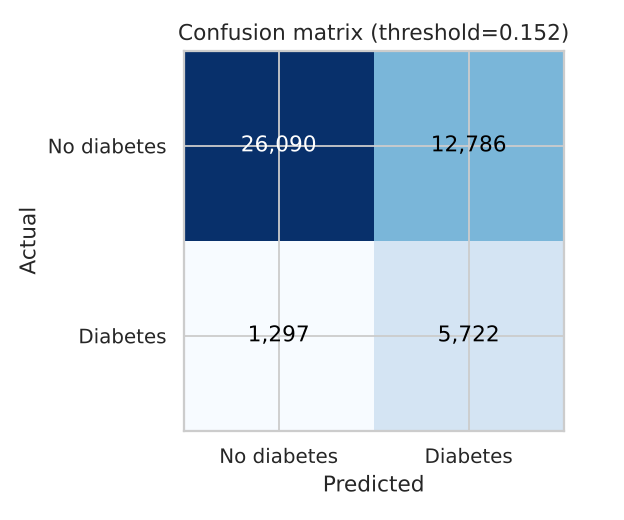

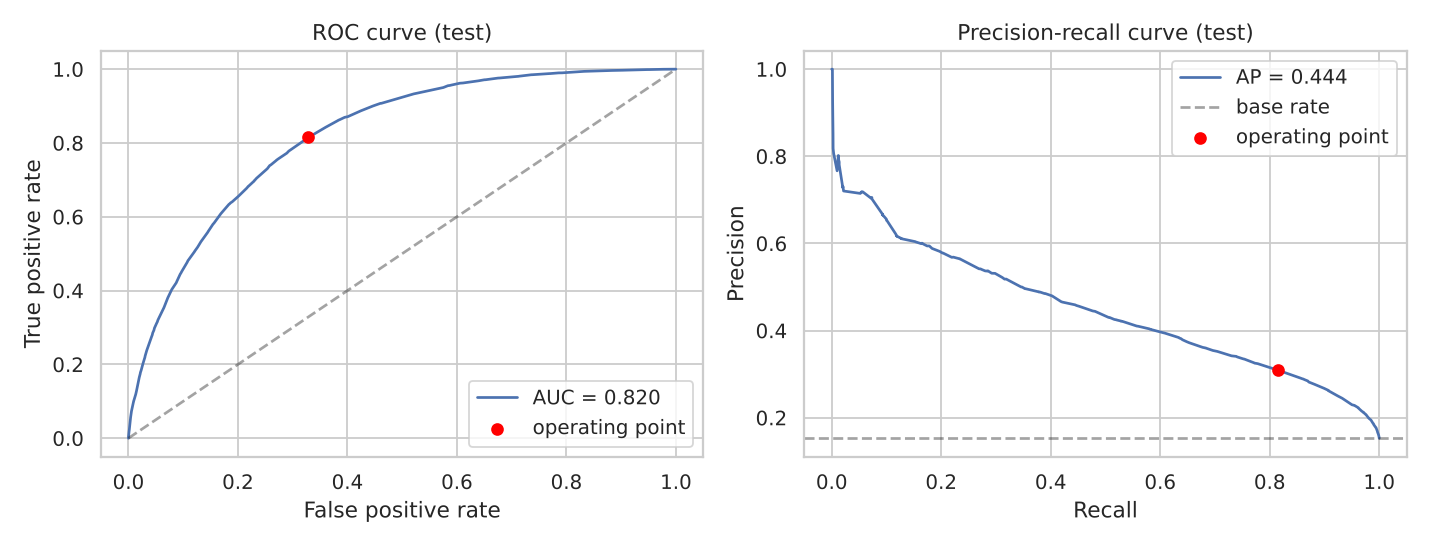

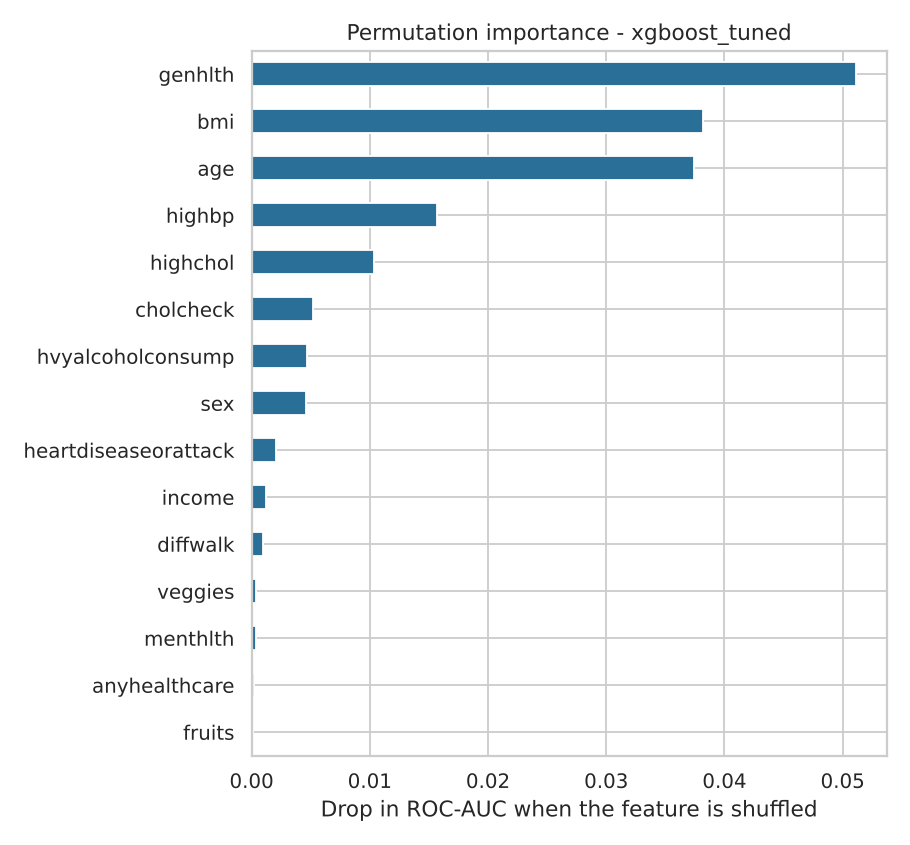

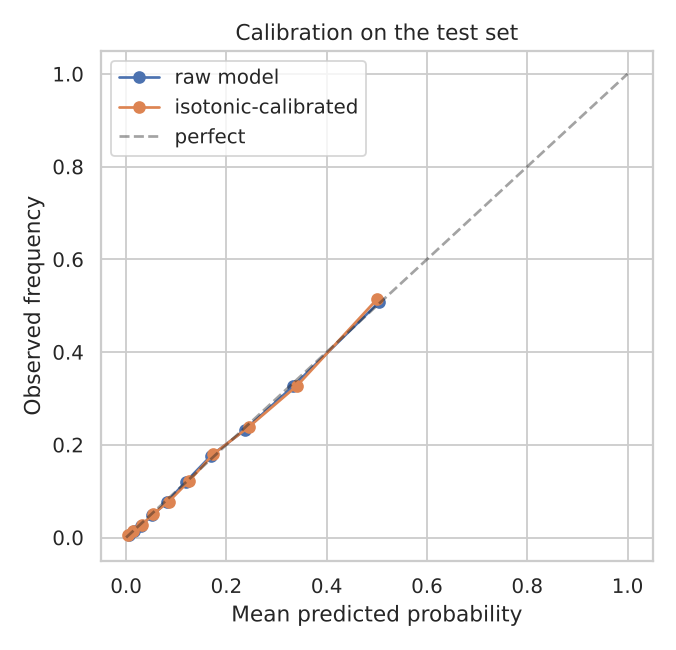

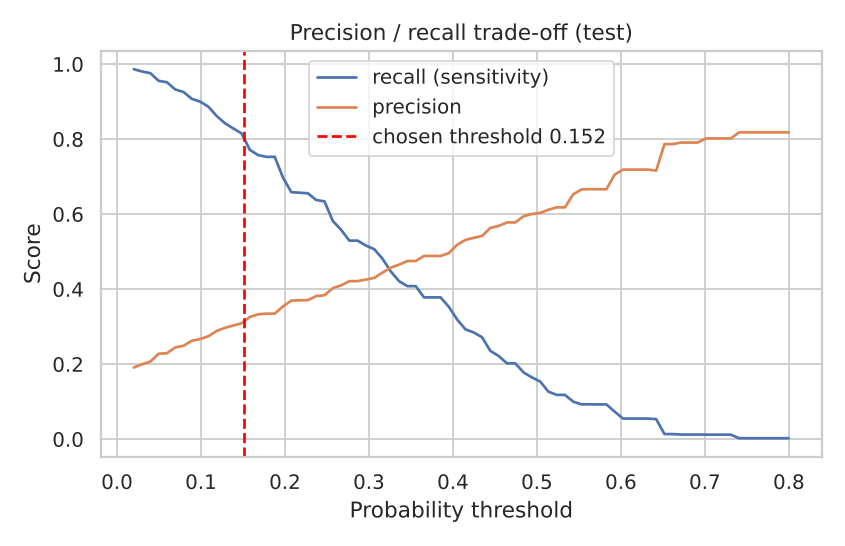

In [15]:
# Trade-off table: thresholds picked on train+val out-of-fold data, evaluated on test
rows = []
for target in (0.70, 0.80, 0.90):
    t = train.pick_threshold(data["y_full"], oof_cal, target)
    rows.append({"target_recall": target, **train.metrics_at(y_test, p_cal, t)})
display(pd.DataFrame(rows).round(3)[["target_recall", "threshold", "recall", "precision", "specificity", "f1", "tp", "fp", "fn", "tn"]])

train.make_figures(final, thr, data, p_raw, p_cal, FIG_DIR, best_name)   # writes figures 05-09
for f in ["05_confusion_matrix", "06_roc_pr_curves", "07_feature_importance", "08_calibration", "09_threshold_tradeoff"]:
    display(Image(FIG_DIR / f"{f}.png", width=620 if f != "06_roc_pr_curves" else 900))

**Interpretation.** At the chosen threshold the model catches 82% of people with diabetes or pre-diabetes and correctly clears
67% of people without it. About 31% of the people it flags are truly positive - roughly twice the 15% base rate, but still
mostly false alarms, which is normal for a cheap first-stage screen followed by a blood test.
Pushing the target recall to 90% lowers specificity to 0.54 and precision to 0.26 (table above): that is the trade-off a clinic would have to price.
Calibration changed the Brier score by only 0.00006: because no class weights are used, the probabilities were already
close to the truth (calibration curve above), so the isotonic step is a safety net, not a large correction.

## 7. Sanity check of the saved artifact
`python train.py` writes `model.bin` and the files in `artifacts/`. Here we load the saved bundle exactly like the API does and compare with this notebook run.

In [16]:
import json
from scoring import load_bundle, predict_one

bundle = load_bundle("model.bin")
sample = json.load(open("sample_request.json"))
print("API-style prediction for sample_request.json:", predict_one(bundle, sample))

saved = json.load(open("artifacts/metrics.json"))
print("metrics.json  ROC-AUC:", round(saved["test_metrics"]["roc_auc"], 4), "| threshold:", round(saved["threshold"], 4))
print("this notebook ROC-AUC:", round(roc_auc_score(y_test, p_cal), 4), "| threshold:", round(thr, 4))

API-style prediction for sample_request.json: {'diabetes_probability': 0.3139047622680664, 'diabetes_prediction': 1, 'threshold': 0.1516042947769165, 'model': 'xgboost_tuned'}
metrics.json  ROC-AUC: 0.8199 | threshold: 0.1516
this notebook ROC-AUC: 0.8199 | threshold: 0.1516


## 8. Conclusions and limitations
- **Model:** tuned XGBoost (`{"subsample": 0.7, "reg_lambda": 1, "n_estimators": 300, "min_child_weight": 1, "max_depth": 6, "learning_rate": 0.03, "colsample_bytree": 0.8}`), isotonic-calibrated, threshold 0.152.
- **Test performance:** ROC-AUC 0.820, average precision 0.444; recall 0.82 / precision 0.31 at the screening threshold.
- **Honest numbers:** de-duplicating the data lowered the headline AUC (the earlier 0.827 partly reflected copies of the same row in train and test).
- **Limits:** self-reported, cross-sectional 2015 survey data; the target mixes diabetes and pre-diabetes; identical answers can have different labels; no lab values.
  The model supports screening decisions only - it is not a diagnostic tool.
- **Next steps:** add HbA1c / glucose or family history if available, fairness checks across sex, age and income groups, and monitoring for data drift after deployment.